##Agent With Mermory 


In [1]:
import os 

from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [4]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory  import InMemorySaver

In [6]:
agent = create_agent(
    model="groq:openai/gpt-oss-120b",
    checkpointer = InMemorySaver()
)

In [ ]:
#create Thread 
config = {"configurable":{"thread_id":"test1"}}

In [9]:
from langchain.messages import  HumanMessage, SystemMessage

response = agent.invoke({"messages":[HumanMessage(content="Hi My Name Is Omkar")]}, config=config)
response

{'messages': [HumanMessage(content='Hi My Name Is Omkar', additional_kwargs={}, response_metadata={}, id='9000db54-c848-4088-852f-6fa310190ce3'),
  AIMessage(content='Hello Omkar! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi My Name Is Omkar". Likely they want a response greeting. We should respond politely. No special instructions.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 77, 'total_tokens': 131, 'completion_time': 0.113707903, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.004073743, 'prompt_tokens_details': None, 'queue_time': 0.318005754, 'total_time': 0.117781646}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e42c-eb28-7404-b715-9bdbb9f04b21-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7

In [10]:
agent.invoke({"messages":[HumanMessage(content="Hi What Is My Name?")]}, config=config)

{'messages': [HumanMessage(content='Hi My Name Is Omkar', additional_kwargs={}, response_metadata={}, id='9000db54-c848-4088-852f-6fa310190ce3'),
  AIMessage(content='Hello Omkar! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi My Name Is Omkar". Likely they want a response greeting. We should respond politely. No special instructions.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 77, 'total_tokens': 131, 'completion_time': 0.113707903, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.004073743, 'prompt_tokens_details': None, 'queue_time': 0.318005754, 'total_time': 0.117781646}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e42c-eb28-7404-b715-9bdbb9f04b21-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7

In [12]:
config1 = {"configurable":{"thread_id":"test2"}}
from langchain.messages import  HumanMessage, SystemMessage

response = agent.invoke({"messages":[HumanMessage(content="Hi My Name Is Krish")]}, config=config1)
response


{'messages': [HumanMessage(content='Hi My Name Is Omkar', additional_kwargs={}, response_metadata={}, id='81a727eb-0840-4045-9858-e79cbe7b038f'),
  AIMessage(content='Hello Omkar! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi My Name Is Omkar". Probably just greet back. Follow policy. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 77, 'total_tokens': 136, 'completion_time': 0.123255023, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.003790267, 'prompt_tokens_details': None, 'queue_time': 0.156542268, 'total_time': 0.12704529}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e431-10eb-73fb-a1a8-d7db6581b60c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'inp

In [13]:
from langchain.messages import  HumanMessage, SystemMessage

response = agent.invoke({"messages":[HumanMessage(content="What Is Is My Name")]}, config=config1)
response

{'messages': [HumanMessage(content='Hi My Name Is Omkar', additional_kwargs={}, response_metadata={}, id='81a727eb-0840-4045-9858-e79cbe7b038f'),
  AIMessage(content='Hello Omkar! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi My Name Is Omkar". Probably just greet back. Follow policy. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 77, 'total_tokens': 136, 'completion_time': 0.123255023, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.003790267, 'prompt_tokens_details': None, 'queue_time': 0.156542268, 'total_time': 0.12704529}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e431-10eb-73fb-a1a8-d7db6581b60c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'inp

Middleware

In [16]:
import os 

from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


Summarization Middleware

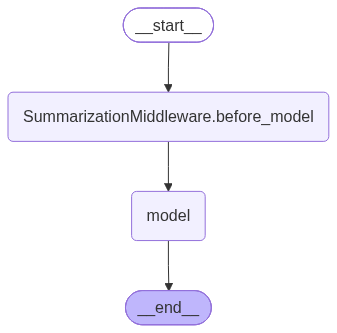

In [21]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage , SystemMessage


## agent with Messagebased summariztion 
agent = create_agent(
    model = "groq:openai/gpt-oss-120b",

    checkpointer = InMemorySaver(),
    middleware = [
        SummarizationMiddleware(

            model  = "groq:openai/gpt-oss-120b",

            trigger = ("messages",10),

            keep = ("messages",4)
        )
    ]
)

agent 


In [22]:
##thread ID 

config = {"configurable":{"thread_id":"test1"}}

In [25]:
questions = [

    "what is 2+2",
    "what is 10*5?",
    "what is 100/5?",
    "what is 15-7?",
    "what is 3*3"
]

for q in questions:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages:{response}")
    print(f"Messages:{len(response['messages'])}")

Messages:{'messages': [HumanMessage(content='Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user is requesting basic arithmetic calculations.\n\n## SUMMARY\n- User asked: “what is 2+2” → AI responded “2\u202f+\u202f2\u202f=\u202f4.”\n- User asked: “what is 10*5?” → AI responded “\\(10 \\times 5 = 50\\).”\n- User asked: “what is 100/5?” → AI responded “\\(100 \\div 5 = 20\\).”\n- User asked: “what is 15-7?” → No answer provided yet.\n\n## ARTIFACTS\nNone.\n\n## NEXT STEPS\nProvide the answer to the pending arithmetic query:\u202f\\(15 - 7 = 8\\).', additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='6eb99dc1-f3a8-441f-a508-cfbfc3111c33'), AIMessage(content='\\(15 - 7 = 8\\).', additional_kwargs={'reasoning_content': 'User is asking simple arithmetic. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 160, 'total_tokens': 189, 'completion_time': 0.061123675, 'completion_tokens_details': {'reaso

Token Size

In [ ]:
from langchain.agents   import  create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver  



@tool
def search_hotels(city: str) -> str:
    """Search for available hotels and their prices in a given city."""

    return f"""Hotels in {city}:
    1. Grand Hotel - 5 star, $350/night, spa, pool, gym
    2. City Inn - 4 star, $180/night, business center
    3. Budget Stay - 3 star, $75/night, free wifi"""


agent = create_agent(

    model = "groq:openai/gpt-oss-120b",
    tools = [search_hotels],
    checkpointer = InMemorySaver(),
    middleware = [SummarizationMiddleware(
        model = "groq:openai/gpt-oss-120b",
        trigger = ("tokens",550),
        keep = ("tokens",200)
    )
    ]
)

config = {"configurable":{"thread_id":"test-1"}}

#Token Counter 
def count_tokens(messages):

    total_chars = sum(len(m.content) for m in messages)
    return total_chars//4  #4 chars = 1 Token

In [31]:
#Run Test

cities = ["Paris","London","Tokyo","New York", "Dubai","Singapore"]

for city in cities:

    response = agent.invoke(
        {"messages":[HumanMessage(content = f"Find The Hotel In {city}")]},

        config = config
    )

    tokens = count_tokens(response['messages'])
    print(f"{city}: ~ {tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response["messages"])}")


Paris: ~ 250 tokens, 4 messages
[HumanMessage(content='Find The Hotel In Paris', additional_kwargs={}, response_metadata={}, id='f31ec0b3-777f-443d-85ae-c36cbeb9305f'), AIMessage(content='', additional_kwargs={'reasoning_content': 'The user says "Find The Hotel In Paris". Likely they want to search for hotels in Paris. Use the function search_hotels with city "Paris".', 'tool_calls': [{'id': 'fc_250d59ae-60a0-41ac-b6bc-df6384837da5', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotels'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 131, 'total_tokens': 192, 'completion_time': 0.129702427, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.007000048, 'prompt_tokens_details': None, 'queue_time': 0.159003412, 'total_time': 0.136702475}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4727af4560', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_pr

Human In The Loop Middleware 

Pause Agent Execution for Human Approval, editing, or rejection of tool calls before execution

In [82]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

def read_email_tool(email_id:str)-> str:

    """Mock Function to read an email by its ID"""

    return f"Email Content for ID: {email_id}"

def send_email_tool(recipient: str, subject : str, body: str)-> str:

    """ Mock Function To Send An Email""" 
    return f"Email sent To {recipient} with Subject {subject}"


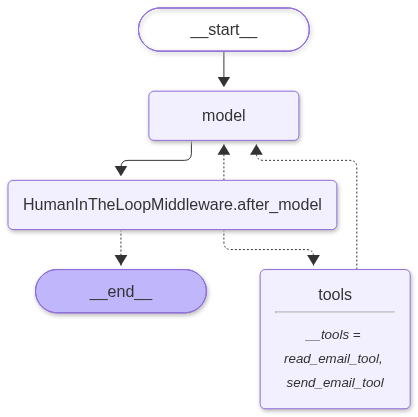

In [95]:
agent = create_agent(

    model = "groq:openai/gpt-oss-120b",

    tools = [read_email_tool , send_email_tool], 

    checkpointer = InMemorySaver(),

    middleware = [
        HumanInTheLoopMiddleware(
            interrupt_on = {
                "send_email_tool":{
                    "allowed_decisions": ["approve","edit","reject"]
                },
                "read_email_tool":False , 
            }
        )
    ]
)

agent 

In [96]:
config = {"configurable":{"thread_id":"test-approve"}}

#step-1: Request
result = agent.invoke(
    {"messages":[HumanMessage(content = "send email to Omkar@example.com with subject 'Hello' and body 'How are you'")]},
    config = config 
)

result
 

{'messages': [HumanMessage(content="send email to Omkar@example.com with subject 'Hello' and body 'How are you'", additional_kwargs={}, response_metadata={}, id='efa77287-15ce-4c8b-8067-fa494ae426b2'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to send email using tool. Use send_email_tool.', 'tool_calls': [{'id': 'fc_4cfc40b7-eb94-41df-8850-ed4a37b46ac9', 'function': {'arguments': '{"body":"How are you","recipient":"Omkar@example.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 176, 'total_tokens': 237, 'completion_time': 0.128476576, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.010840355, 'prompt_tokens_details': None, 'queue_time': 0.280675294, 'total_time': 0.139316931}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_df9620fe21', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 

#Approve

In [97]:
from langgraph.types import Command

if "__interrupt__" in result:

    print("Approving")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type":"approve"}
                ]
            }
        ),
        config = config
    )
    print(f"Result : {result['messages'][-1].content}")

Approving
Result : Your email has been sent to **Omkar@example.com** with the subject **“Hello”** and the body “How are you.” Let me know if there’s anything else you’d like to do!


#Reject

In [101]:

from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


def read_email_tool(email_id: str) -> str:
    """Read an email using its email ID."""
    return f"Email content for ID: {email_id}"


def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Send an email with recipient, subject and body."""
    return f"Email sent to {recipient} with subject {subject}"


agent = create_agent(
    model="groq:openai/gpt-oss-120b",

    tools=[read_email_tool, send_email_tool],

    checkpointer=InMemorySaver(),

    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool": {
                    "allowed_decisions": ["approve", "edit", "reject"]
                },
                "read_email_tool": False
            }
        )
    ]
)


In [103]:
#step 2 : Reject 
from langgraph.types import Command
if "__interrupt__" in result:

    print("Paused ! Approved...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type": "reject"}
                ]
            }
        ),
        config = config 

    )

    print(f"Result : {result['messages'][-1].content}")

#Editing

In [104]:

from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


def read_email_tool(email_id: str) -> str:
    """Read an email using its email ID."""
    return f"Email content for ID: {email_id}"


def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Send an email with recipient, subject and body."""
    return f"Email sent to {recipient} with subject {subject}"


agent = create_agent(
    model="groq:openai/gpt-oss-120b",

    tools=[read_email_tool, send_email_tool],

    checkpointer=InMemorySaver(),

    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool": {
                    "allowed_decisions": ["approve", "edit", "reject"]
                },
                "read_email_tool": False
            }
        )
    ]
)


In [105]:
config  ={"configurable":{"thread_id":"test-edit"}}

#step1 :- Request

result =  agent.invoke(
    {
        "messages": [HumanMessage(content = "send email To Wrong@email.com with subject 'Test' and Body 'Hello'")]
    },
    config = config 
)

In [106]:
result 

{'messages': [HumanMessage(content="send email To Wrong@email.com with subject 'Test' and Body 'Hello'", additional_kwargs={}, response_metadata={}, id='4f853d8f-cb57-43a9-a807-dde16769798b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants to send an email. We need to use send_email_tool with recipient, subject, body. Provide correct parameters.', 'tool_calls': [{'id': 'fc_cbf733e0-8131-454e-acd7-9f659e67e35e', 'function': {'arguments': '{"body":"Hello","recipient":"Wrong@email.com","subject":"Test"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 173, 'total_tokens': 244, 'completion_time': 0.148812263, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.00901155, 'prompt_tokens_details': None, 'queue_time': 0.368927929, 'total_time': 0.157823813}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_90620edd96', 'service_tier': 'on_demand', 

In [108]:
# Step 2: Edit and approve
if "__interrupt__" in result:
    print("⏸️ Paused! Editing...")

    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {
                        "type": "edit",
                        "edited_action": {
                            "name": "send_email_tool",  # Tool name
                            "args": {                   # New arguments
                                "recipient": "correct@email.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )


⏸️ Paused! Editing...


In [109]:
result

{'messages': [HumanMessage(content="send email To Wrong@email.com with subject 'Test' and Body 'Hello'", additional_kwargs={}, response_metadata={}, id='4f853d8f-cb57-43a9-a807-dde16769798b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants to send an email. We need to use send_email_tool with recipient, subject, body. Provide correct parameters.', 'tool_calls': [{'id': 'fc_cbf733e0-8131-454e-acd7-9f659e67e35e', 'function': {'arguments': '{"body":"Hello","recipient":"Wrong@email.com","subject":"Test"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 173, 'total_tokens': 244, 'completion_time': 0.148812263, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.00901155, 'prompt_tokens_details': None, 'queue_time': 0.368927929, 'total_time': 0.157823813}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_90620edd96', 'service_tier': 'on_demand', 